# An Interpretable Clinical Hematological Signature-Based ML Framework for Dengue Detection

**D-CHSS (Dengue Clinical Hematological Signature Score)** — CBC-derived interpretable signature
combined with raw CBC, reference-range deviations, and clinically-established hematological ratios.

**Key Fix in this version:** Predicted probabilities are explicitly **calibrated (Isotonic Regression)**
so that probability values genuinely reflect risk (e.g., ~20% vs ~90% should mean clearly different
dengue likelihood) instead of clustering in a narrow range. A reliability table and probability
distribution analysis are added to make this verifiable.

**Disclaimer:** Research demonstration only — NOT a medical diagnostic tool.

In [128]:
import sys, subprocess

def install_if_missing(pkg, pip_name=None):
    try:
        __import__(pkg)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pip_name or pkg])

install_if_missing("xgboost")
install_if_missing("shap")
install_if_missing("statsmodels")
install_if_missing("imblearn", "imbalanced-learn")

import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.model_selection import (train_test_split, StratifiedKFold, GridSearchCV,
                                      RandomizedSearchCV, cross_val_score, cross_val_predict)
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, VotingClassifier, StackingClassifier
from sklearn.svm import SVC
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                              roc_auc_score, average_precision_score, matthews_corrcoef,
                              confusion_matrix, roc_curve, precision_recall_curve, brier_score_loss)

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

from scipy.stats import mannwhitneyu, spearmanr

import xgboost as xgb
import shap

from statsmodels.stats.contingency_tables import mcnemar

import pickle

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

plt.rcParams['figure.figsize'] = (8, 5)
plt.rcParams['font.size'] = 11

print("Libraries loaded successfully.")

Libraries loaded successfully.


In [129]:
DATA_PATH = "/kaggle/input/datasets/musabbir22/dengue-dataset5/Dengue Fever Hematological Dataset.csv"

df = pd.read_csv(DATA_PATH)

print("Dataset Shape:", df.shape)
print("\nColumn Names:\n", df.columns.tolist())
df.head()

Dataset Shape: (1523, 19)

Column Names:
 ['Gender', 'Age', 'Hemoglobin(g/dl)', 'Neutrophils(%)', 'Lymphocytes(%)', 'Monocytes(%)', 'Eosinophils(%)', 'RBC', 'HCT(%)', 'MCV(fl)', 'MCH(pg)', 'MCHC(g/dl)', 'RDW-CV(%)', 'Total Platelet Count(/cumm)', 'MPV(fl)', 'PDW(%)', 'PCT(%)', 'Total WBC count(/cumm)', 'Result']


,Gender,Age,Hemoglobin(g/dl),Neutrophils(%),Lymphocytes(%),Monocytes(%),Eosinophils(%),RBC,HCT(%),MCV(fl),MCH(pg),MCHC(g/dl),RDW-CV(%),Total Platelet Count(/cumm),MPV(fl),PDW(%),PCT(%),Total WBC count(/cumm),Result
0,Male,21,14.8,48,47,3,2,5,48.00,96.0,29.60,30.8,11.6,112000,10.70,15.40,0.120,5100,positive
1,Male,30,15.0,47,49,6,3,5,49.80,96.1,28.40,29.5,11.8,96000,10.60,15.80,0.121,4500,positive
2,Male,51,16.3,41,48,4,5,5,50.10,93.5,31.30,32.7,13.5,184000,10.40,16.40,0.130,6000,negative
3,Female,26,12.3,46,49,7,5,5,44.00,90.0,30.50,30.5,14.7,167000,8.10,17.10,0.110,5000,negative
4,Male,35,16.1,45,46,4,4,5,50.53,91.0,29.12,29.2,15.2,155000,10.52,12.34,0.150,4600,negative


In [130]:
gender_col_raw = [c for c in df.columns if 'gender' in c.lower() or 'sex' in c.lower()]
result_col_raw = [c for c in df.columns if 'result' in c.lower() or 'dengue' in c.lower()
                   or 'outcome' in c.lower() or 'diagnosis' in c.lower()]

print("Detected Gender column(s):", gender_col_raw)
print("Detected Result column(s):", result_col_raw)

if gender_col_raw:
    print("\nUnique values in Gender column:", df[gender_col_raw[0]].unique())
if result_col_raw:
    print("Unique values in Result column:", df[result_col_raw[0]].unique())

Detected Gender column(s): ['Gender']
Detected Result column(s): ['Result']

Unique values in Gender column: ['Male' 'Female']
Unique values in Result column: ['positive' 'negative']


In [131]:
def map_columns(columns):
    colmap = {}
    for col in columns:
        c = col.lower().strip()
        if c == 'age' or c.startswith('age'):
            colmap[col] = 'age'
        elif 'gender' in c or 'sex' in c:
            colmap[col] = 'gender'
        elif 'hemoglobin' in c:
            colmap[col] = 'hemoglobin'
        elif 'neutrophil' in c:
            colmap[col] = 'neutrophils'
        elif 'lymphocyte' in c:
            colmap[col] = 'lymphocytes'
        elif 'monocyte' in c:
            colmap[col] = 'monocytes'
        elif 'eosinophil' in c:
            colmap[col] = 'eosinophils'
        elif 'rbc' in c:
            colmap[col] = 'rbc'
        elif 'hct' in c or 'hematocrit' in c:
            colmap[col] = 'hct'
        elif 'mcv' in c:
            colmap[col] = 'mcv'
        elif 'mchc' in c:
            colmap[col] = 'mchc'
        elif 'mch' in c:
            colmap[col] = 'mch'
        elif 'rdw' in c:
            colmap[col] = 'rdw_cv'
        elif 'platelet' in c:
            colmap[col] = 'platelet'
        elif 'mpv' in c:
            colmap[col] = 'mpv'
        elif 'pdw' in c:
            colmap[col] = 'pdw'
        elif 'pct' in c:
            colmap[col] = 'pct'
        elif 'wbc' in c or 'white blood' in c:
            colmap[col] = 'wbc'
        elif 'result' in c or 'diagnosis' in c or 'outcome' in c or 'dengue' in c:
            colmap[col] = 'result'
        else:
            colmap[col] = c
    return colmap

colmap = map_columns(df.columns)
df = df.rename(columns=colmap)
print("Mapped Columns:", df.columns.tolist())

CBC_FEATURES = ['hemoglobin', 'neutrophils', 'lymphocytes', 'monocytes', 'eosinophils',
                'rbc', 'hct', 'mcv', 'mch', 'mchc', 'rdw_cv', 'platelet', 'mpv', 'pdw', 'pct', 'wbc']

def encode_gender(series):
    mapping = {}
    for v in series.dropna().unique():
        v_str = str(v).strip().lower()
        mapping[v] = 1 if v_str.startswith('m') else (0 if v_str.startswith('f') else -1)
    return series.map(mapping), mapping

df['gender_enc'], gender_mapping = encode_gender(df['gender'])
print("\nGender Mapping:", gender_mapping)

def encode_result(series):
    mapping = {}
    pos_keywords = ['positive', 'pos', 'yes', 'reactive', '1']
    for v in series.dropna().unique():
        v_str = str(v).strip().lower()
        mapping[v] = 1 if any(k == v_str or k in v_str for k in pos_keywords) else 0
    return series.map(mapping), mapping

df['result_bin'], result_mapping = encode_result(df['result'])
print("Result Mapping:", result_mapping)

Mapped Columns: ['gender', 'age', 'hemoglobin', 'neutrophils', 'lymphocytes', 'monocytes', 'eosinophils', 'rbc', 'hct', 'mcv', 'mch', 'mchc', 'rdw_cv', 'platelet', 'mpv', 'pdw', 'pct', 'wbc', 'result']

Gender Mapping: {'Male': 1, 'Female': 0}
Result Mapping: {'positive': 1, 'negative': 0}


In [132]:
print("Rows, Columns:", df.shape)
print("\nMissing Values:\n", df.isnull().sum().sum())
print("Duplicate Rows:", df.duplicated().sum())
df.info()

Rows, Columns: (1523, 21)

Missing Values:
 0
Duplicate Rows: 12
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1523 entries, 0 to 1522
Data columns (total 21 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   gender       1523 non-null   object 
 1   age          1523 non-null   int64  
 2   hemoglobin   1523 non-null   float64
 3   neutrophils  1523 non-null   int64  
 4   lymphocytes  1523 non-null   int64  
 5   monocytes    1523 non-null   int64  
 6   eosinophils  1523 non-null   int64  
 7   rbc          1523 non-null   int64  
 8   hct          1523 non-null   float64
 9   mcv          1523 non-null   float64
 10  mch          1523 non-null   float64
 11  mchc         1523 non-null   float64
 12  rdw_cv       1523 non-null   float64
 13  platelet     1523 non-null   int64  
 14  mpv          1523 non-null   float64
 15  pdw          1523 non-null   float64
 16  pct          1523 non-null   float64
 17  wbc          1523 non-nul

In [133]:
df[['age'] + CBC_FEATURES].describe().T

,count,mean,std,min,25%,50%,75%,max
age,1523.0,40.310571,15.286190,5.00000,28.000,39.000,53.000,78.000
hemoglobin,1523.0,14.513451,1.627142,10.40000,13.200,14.600,15.800,17.500
neutrophils,1523.0,44.484570,4.344736,29.00000,42.000,45.000,48.000,60.000
lymphocytes,1523.0,43.559422,4.972815,29.00000,41.000,44.000,47.000,56.000
monocytes,1523.0,3.270519,1.209507,2.00000,2.000,3.000,4.000,9.000
eosinophils,1523.0,3.083388,1.000791,1.00000,2.000,3.000,4.000,9.000
rbc,1523.0,4.765594,0.722874,4.00000,4.000,5.000,5.000,7.000
hct,1523.0,45.189280,3.566435,36.30000,42.595,45.550,47.840,51.980
mcv,1523.0,89.815561,5.515619,80.00000,85.100,89.700,94.200,100.000
mch,1523.0,29.897225,2.026022,22.90000,28.400,30.000,31.400,34.000


Class Counts:
 result_bin
1    1042
0     481
Name: count, dtype: int64

Class Percentages:
 result_bin
1    68.417597
0    31.582403
Name: proportion, dtype: float64


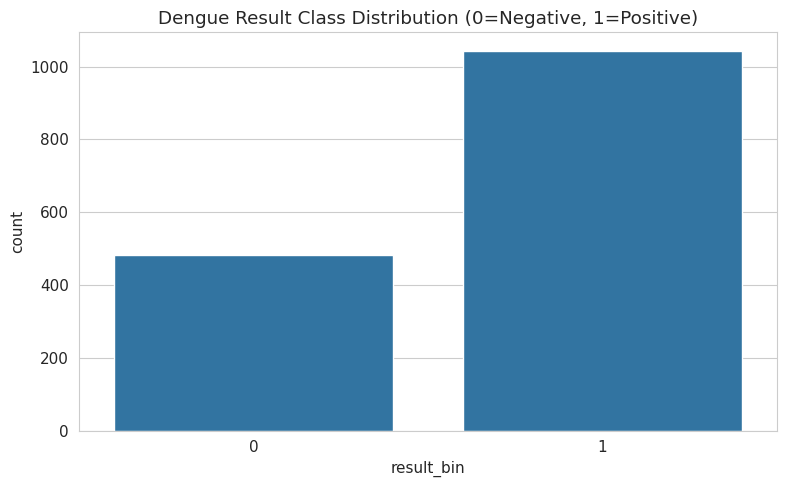

In [134]:
counts = df['result_bin'].value_counts()
percentages = df['result_bin'].value_counts(normalize=True) * 100
print("Class Counts:\n", counts)
print("\nClass Percentages:\n", percentages)

plt.figure()
sns.countplot(x='result_bin', data=df)
plt.title("Dengue Result Class Distribution (0=Negative, 1=Positive)")
plt.tight_layout()
plt.show()

In [135]:
n_before = df.shape[0]
df = df.drop_duplicates().reset_index(drop=True)
print("Rows Before:", n_before, "| Rows After:", df.shape[0])

Rows Before: 1523 | Rows After: 1511


In [136]:
y_all = df['result_bin'].copy()

df_train, df_test, y_train, y_test = train_test_split(
    df.copy(), y_all, test_size=0.20, stratify=y_all, random_state=RANDOM_STATE
)
df_train = df_train.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)
y_train = y_train.reset_index(drop=True)
y_test = y_test.reset_index(drop=True)

print("Train Shape:", df_train.shape, "| Test Shape:", df_test.shape)
print("Train class %:\n", y_train.value_counts(normalize=True))
print("Test class %:\n", y_test.value_counts(normalize=True))

Train Shape: (1208, 21) | Test Shape: (303, 21)
Train class %:
 result_bin
1    0.684603
0    0.315397
Name: proportion, dtype: float64
Test class %:
 result_bin
1    0.686469
0    0.313531
Name: proportion, dtype: float64


In [137]:
num_cols = ['age'] + CBC_FEATURES
cat_cols = ['gender_enc']

imputer_num = SimpleImputer(strategy='median')
imputer_cat = SimpleImputer(strategy='most_frequent')

imputer_num.fit(df_train[num_cols])
imputer_cat.fit(df_train[cat_cols])

df_train[num_cols] = imputer_num.transform(df_train[num_cols])
df_test[num_cols] = imputer_num.transform(df_test[num_cols])
df_train[cat_cols] = imputer_cat.transform(df_train[cat_cols])
df_test[cat_cols] = imputer_cat.transform(df_test[cat_cols])

print("Missing after imputation - train:", df_train[num_cols+cat_cols].isnull().sum().sum(),
      "test:", df_test[num_cols+cat_cols].isnull().sum().sum())

Missing after imputation - train: 0 test: 0


In [138]:
X_raw_train = df_train[CBC_FEATURES].copy()
X_raw_test = df_test[CBC_FEATURES].copy()
print("CBC-only feature shape:", X_raw_train.shape)

CBC-only feature shape: (1208, 16)


In [139]:
REFERENCE_RANGES = {
    'hemoglobin': {'male': (13.0, 17.0), 'female': (12.0, 15.5), 'default': (12.0, 17.0)},
    'rbc':        {'male': (4.5, 5.5),   'female': (4.0, 5.0),   'default': (4.0, 5.5)},
    'hct':        {'male': (40.0, 50.0), 'female': (36.0, 44.0), 'default': (36.0, 50.0)},
    'neutrophils': (40.0, 70.0),
    'lymphocytes': (20.0, 40.0),
    'monocytes':   (2.0, 8.0),
    'eosinophils': (1.0, 6.0),
    'mcv':         (80.0, 100.0),
    'mch':         (27.0, 33.0),
    'mchc':        (32.0, 36.0),
    'rdw_cv':      (11.5, 14.5),
    'platelet':    (150000.0, 450000.0),
    'mpv':         (7.5, 11.5),
    'pdw':         (9.0, 17.0),
    'pct':         (0.17, 0.35),
    'wbc':         (4000.0, 11000.0)
}
SEX_SPECIFIC_PARAMS = ['hemoglobin', 'rbc', 'hct']

def get_range(param, gender_val):
    r = REFERENCE_RANGES[param]
    if isinstance(r, dict):
        return r['male'] if gender_val == 1 else (r['female'] if gender_val == 0 else r['default'])
    return r

print("Reference ranges defined for", len(REFERENCE_RANGES), "parameters.")

Reference ranges defined for 16 parameters.


In [140]:
MAX_DEV = 3.0  # cap deviation at 300% to prevent one extreme value dominating

def compute_deviation(data, param):
    genders = data['gender_enc'].values
    L_arr = np.zeros(len(data)); U_arr = np.zeros(len(data))
    for i, g in enumerate(genders):
        L, U = get_range(param, g)
        L_arr[i], U_arr[i] = L, U
    x = data[param].values.astype(float)
    dev = np.zeros(len(x))
    low_mask = x < L_arr; high_mask = x > U_arr
    dev[low_mask] = -(L_arr[low_mask] - x[low_mask]) / L_arr[low_mask]
    dev[high_mask] = (x[high_mask] - U_arr[high_mask]) / U_arr[high_mask]
    return np.clip(dev, -MAX_DEV, MAX_DEV)

def add_deviation_features(data):
    data = data.copy()
    for param in CBC_FEATURES:
        data[f'{param}_dev'] = compute_deviation(data, param)
    return data

df_train = add_deviation_features(df_train)
df_test = add_deviation_features(df_test)
DEV_FEATURES = [f'{p}_dev' for p in CBC_FEATURES]
X_dev_train = df_train[DEV_FEATURES].copy()
X_dev_test = df_test[DEV_FEATURES].copy()
print("Deviation features created.")

Deviation features created.


In [141]:
def compute_state(data, param):
    states = []
    for val, g in zip(data[param], data['gender_enc']):
        L, U = get_range(param, g)
        states.append('LOW' if val < L else ('HIGH' if val > U else 'NORMAL'))
    return states

def add_state_features(data):
    data = data.copy()
    for param in CBC_FEATURES:
        data[f'{param}_state'] = compute_state(data, param)
    return data

df_train = add_state_features(df_train)
df_test = add_state_features(df_test)
print("State features created.")

State features created.


In [142]:
THROMBO_PARAMS = ['platelet', 'mpv', 'pdw', 'pct']
LEUKO_PARAMS = ['wbc', 'neutrophils', 'lymphocytes', 'monocytes', 'eosinophils']
HEMO_PARAMS = ['hct', 'hemoglobin', 'rbc']

def compute_component_raw(data, params):
    dev_cols = [f'{p}_dev' for p in params]
    return data[dev_cols].abs().mean(axis=1)

df_train['TS_raw'] = compute_component_raw(df_train, THROMBO_PARAMS)
df_test['TS_raw']  = compute_component_raw(df_test, THROMBO_PARAMS)
df_train['LS_raw'] = compute_component_raw(df_train, LEUKO_PARAMS)
df_test['LS_raw']  = compute_component_raw(df_test, LEUKO_PARAMS)
df_train['HS_raw'] = compute_component_raw(df_train, HEMO_PARAMS)
df_test['HS_raw']  = compute_component_raw(df_test, HEMO_PARAMS)

df_train[['TS_raw','LS_raw','HS_raw']].describe()

,TS_raw,LS_raw,HS_raw
count,1208.000000,1208.000000,1208.000000
mean,0.089695,0.024428,0.029452
std,0.088594,0.024405,0.031436
min,0.000000,0.000000,0.000000
25%,0.016176,0.005000,0.000576
50%,0.073529,0.020000,0.025641
75%,0.129719,0.040000,0.041617
max,0.870000,0.234242,0.207820


In [143]:
def add_ratio_features(data):
    data = data.copy()
    eps = 1e-6
    data['nlr'] = data['neutrophils'] / (data['lymphocytes'] + eps)
    data['plr'] = data['platelet'] / (data['lymphocytes'] + eps)
    data['lmr'] = data['lymphocytes'] / (data['monocytes'] + eps)
    data['pdw_mpv_ratio'] = data['pdw'] / (data['mpv'] + eps)
    data['rdw_platelet_ratio'] = data['rdw_cv'] / (data['platelet'] + eps) * 1000
    return data

df_train = add_ratio_features(df_train)
df_test = add_ratio_features(df_test)
RATIO_FEATURES = ['nlr', 'plr', 'lmr', 'pdw_mpv_ratio', 'rdw_platelet_ratio']
df_train[RATIO_FEATURES].describe()

,nlr,plr,lmr,pdw_mpv_ratio,rdw_platelet_ratio
count,1208.000000,1208.000000,1208.000000,1208.000000,1208.000000
mean,1.043415,3998.731647,14.853514,1.609443,0.091861
std,0.202608,1443.519925,5.004598,0.205351,0.039747
min,0.600000,1359.999973,3.777777,0.813875,0.036769
25%,0.931818,2851.722159,10.999997,1.460036,0.058592
50%,1.000000,3791.321141,13.999995,1.589520,0.083021
75%,1.116279,5116.309835,19.124990,1.733623,0.117801
max,2.068965,9266.666358,24.999988,2.209617,0.226176


In [144]:
component_scaler = StandardScaler()
component_scaler.fit(df_train[['TS_raw', 'LS_raw', 'HS_raw']])

train_std = component_scaler.transform(df_train[['TS_raw', 'LS_raw', 'HS_raw']])
test_std = component_scaler.transform(df_test[['TS_raw', 'LS_raw', 'HS_raw']])

df_train['TS_std'], df_train['LS_std'], df_train['HS_std'] = train_std[:,0], train_std[:,1], train_std[:,2]
df_test['TS_std'], df_test['LS_std'], df_test['HS_std'] = test_std[:,0], test_std[:,1], test_std[:,2]

weight_logreg = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
weight_logreg.fit(df_train[['TS_std','LS_std','HS_std']], y_train)

abs_coefs = np.abs(weight_logreg.coef_[0])
weights = abs_coefs / abs_coefs.sum()
w_ts, w_ls, w_hs = weights

print(f"D-CHSS weights: w_ts={w_ts:.4f}, w_ls={w_ls:.4f}, w_hs={w_hs:.4f}")

df_train['DCHSS'] = w_ts*df_train['TS_std'] + w_ls*df_train['LS_std'] + w_hs*df_train['HS_std']
df_test['DCHSS'] = w_ts*df_test['TS_std'] + w_ls*df_test['LS_std'] + w_hs*df_test['HS_std']

DCHSS_COMPONENT_FEATURES = ['TS_std', 'LS_std', 'HS_std', 'DCHSS']

D-CHSS weights: w_ts=0.1446, w_ls=0.5689, w_hs=0.2865


In [145]:
scaler_raw = StandardScaler()
scaler_raw.fit(X_raw_train)
X_raw_train_scaled = pd.DataFrame(scaler_raw.transform(X_raw_train), columns=CBC_FEATURES)
X_raw_test_scaled = pd.DataFrame(scaler_raw.transform(X_raw_test), columns=CBC_FEATURES)

cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
print("Ready.")

Ready.


In [146]:
param_grids = {
    'Logistic Regression': {'C': [0.01, 0.1, 1, 10], 'class_weight': [None, 'balanced']},
    'Decision Tree': {'max_depth': [3,5,7,None], 'min_samples_split':[2,5,10], 'class_weight':[None,'balanced']},
    'Random Forest': {'n_estimators':[100,200,300], 'max_depth':[5,10,None], 'class_weight':[None,'balanced']},
    'SVM': {'C':[0.1,1,10], 'gamma':['scale','auto'], 'class_weight':[None,'balanced']},
    'XGBoost': {'n_estimators':[100,200], 'max_depth':[3,5], 'learning_rate':[0.01,0.1]}
}
base_estimators = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    'Decision Tree': DecisionTreeClassifier(random_state=RANDOM_STATE),
    'Random Forest': RandomForestClassifier(random_state=RANDOM_STATE),
    'SVM': SVC(probability=True, random_state=RANDOM_STATE),
    'XGBoost': xgb.XGBClassifier(random_state=RANDOM_STATE, eval_metric='logloss')
}

best_models = {}
for name, est in base_estimators.items():
    X_use = X_raw_train_scaled if name in ['Logistic Regression','SVM'] else X_raw_train
    grid = GridSearchCV(est, param_grids[name], cv=cv_strategy, scoring='roc_auc', n_jobs=-1)
    grid.fit(X_use, y_train)
    best_models[name] = grid.best_estimator_
    print(f"{name}: CV ROC-AUC={grid.best_score_:.4f}")

Logistic Regression: CV ROC-AUC=0.6470
Decision Tree: CV ROC-AUC=0.6634
Random Forest: CV ROC-AUC=0.6892
SVM: CV ROC-AUC=0.6736
XGBoost: CV ROC-AUC=0.6879


In [147]:
def calculate_metrics(y_true, y_pred, y_prob):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0
    return {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred, zero_division=0),
        'Recall': recall_score(y_true, y_pred, zero_division=0),
        'Specificity': specificity,
        'F1': f1_score(y_true, y_pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_true, y_prob),
        'PR-AUC': average_precision_score(y_true, y_prob),
        'MCC': matthews_corrcoef(y_true, y_pred)
    }

baseline_test_metrics = {}
for name, model in best_models.items():
    X_use_test = X_raw_test_scaled if name in ['Logistic Regression','SVM'] else X_raw_test
    y_pred = model.predict(X_use_test)
    y_prob = model.predict_proba(X_use_test)[:, 1]
    baseline_test_metrics[name] = calculate_metrics(y_test, y_pred, y_prob)

baseline_results_df = pd.DataFrame(baseline_test_metrics).T
baseline_results_df

,Accuracy,Precision,Recall,Specificity,F1,ROC-AUC,PR-AUC,MCC
Logistic Regression,0.617162,0.732323,0.697115,0.442105,0.714286,0.621609,0.747756,0.135728
Decision Tree,0.749175,0.761905,0.923077,0.368421,0.834783,0.633376,0.748849,0.361446
Random Forest,0.759076,0.752809,0.966346,0.305263,0.846316,0.663512,0.768235,0.389432
SVM,0.719472,0.717314,0.975962,0.157895,0.826884,0.658426,0.781649,0.250106
XGBoost,0.755776,0.748148,0.971154,0.284211,0.845188,0.668370,0.775819,0.380290


In [148]:
X_dchss_train = df_train[DCHSS_COMPONENT_FEATURES].copy()
X_dchss_test = df_test[DCHSS_COMPONENT_FEATURES].copy()

FULL_FEATURES = CBC_FEATURES + DEV_FEATURES + DCHSS_COMPONENT_FEATURES + RATIO_FEATURES
X_full_train = df_train[FULL_FEATURES].copy()
X_full_test = df_test[FULL_FEATURES].copy()

neg_count = (y_train == 0).sum()
pos_count = (y_train == 1).sum()
scale_pos_weight_value = neg_count / pos_count
print("Feature counts -> Full:", X_full_train.shape[1])
print("scale_pos_weight:", round(scale_pos_weight_value, 4))

Feature counts -> Full: 41
scale_pos_weight: 0.4607


## Wider Hyperparameter Search + SMOTE Candidate

Besides the imbalance-aware XGBoost search, we also test an **SMOTE-augmented XGBoost**
candidate. SMOTE is applied **only inside each training fold** via an imblearn Pipeline —
never on the test set or before the split — to avoid leakage (Rule 5 compliant).

In [149]:
param_dist = {
    'n_estimators': [100, 150, 200, 300, 400, 500],
    'max_depth': [3, 4, 5, 6, 7, 8, 10],
    'learning_rate': [0.01, 0.03, 0.05, 0.07, 0.1, 0.15, 0.2],
    'subsample': [0.6, 0.7, 0.8, 0.9, 1.0],
    'colsample_bytree': [0.6, 0.7, 0.8, 0.9, 1.0],
    'min_child_weight': [1, 3, 5, 7],
    'gamma': [0, 0.1, 0.2, 0.3],
    'scale_pos_weight': [1, scale_pos_weight_value]
}

xgb_random_search = RandomizedSearchCV(
    xgb.XGBClassifier(random_state=RANDOM_STATE, eval_metric='logloss'),
    param_distributions=param_dist, n_iter=100, cv=cv_strategy,
    scoring='roc_auc', n_jobs=-1, random_state=RANDOM_STATE
)
xgb_random_search.fit(X_full_train, y_train)
dchss_best_params = xgb_random_search.best_params_
print(f"Best CV ROC-AUC (XGBoost, no SMOTE): {xgb_random_search.best_score_:.4f}")
print("Best Params:", dchss_best_params)

Best CV ROC-AUC (XGBoost, no SMOTE): 0.6899
Best Params: {'subsample': 0.7, 'scale_pos_weight': np.float64(0.4607013301088271), 'n_estimators': 100, 'min_child_weight': 3, 'max_depth': 3, 'learning_rate': 0.03, 'gamma': 0.2, 'colsample_bytree': 0.8}


In [150]:
smote_pipeline = ImbPipeline([
    ('smote', SMOTE(random_state=RANDOM_STATE)),
    ('xgb', xgb.XGBClassifier(**dchss_best_params, random_state=RANDOM_STATE, eval_metric='logloss'))
])

smote_cv_auc = cross_val_score(smote_pipeline, X_full_train, y_train, cv=cv_strategy, scoring='roc_auc')
print(f"SMOTE + XGBoost CV ROC-AUC: {smote_cv_auc.mean():.4f} +/- {smote_cv_auc.std():.4f}")

SMOTE + XGBoost CV ROC-AUC: 0.6756 +/- 0.0434


In [151]:
model_A = xgb.XGBClassifier(**dchss_best_params, random_state=RANDOM_STATE, eval_metric='logloss')
model_A.fit(X_raw_train, y_train)
y_prob_A = model_A.predict_proba(X_raw_test)[:, 1]
y_pred_A = (y_prob_A >= 0.5).astype(int)
metrics_A = calculate_metrics(y_test, y_pred_A, y_prob_A)

model_B = xgb.XGBClassifier(**dchss_best_params, random_state=RANDOM_STATE, eval_metric='logloss')
model_B.fit(X_dev_train, y_train)
y_prob_B = model_B.predict_proba(X_dev_test)[:, 1]
y_pred_B = (y_prob_B >= 0.5).astype(int)
metrics_B = calculate_metrics(y_test, y_pred_B, y_prob_B)

model_C = xgb.XGBClassifier(**dchss_best_params, random_state=RANDOM_STATE, eval_metric='logloss')
model_C.fit(X_dchss_train, y_train)
y_prob_C = model_C.predict_proba(X_dchss_test)[:, 1]
y_pred_C = (y_prob_C >= 0.5).astype(int)
metrics_C = calculate_metrics(y_test, y_pred_C, y_prob_C)

print("Model A (Raw CBC):", {k: round(v,4) for k,v in metrics_A.items()})
print("Model B (Deviation):", {k: round(v,4) for k,v in metrics_B.items()})
print("Model C (D-CHSS):", {k: round(v,4) for k,v in metrics_C.items()})

Model A (Raw CBC): {'Accuracy': 0.7459, 'Precision': 0.7718, 'Recall': 0.8942, 'Specificity': np.float64(0.4211), 'F1': 0.8285, 'ROC-AUC': np.float64(0.6521), 'PR-AUC': np.float64(0.7659), 'MCC': np.float64(0.3626)}
Model B (Deviation): {'Accuracy': 0.7327, 'Precision': 0.7571, 'Recall': 0.899, 'Specificity': np.float64(0.3684), 'F1': 0.822, 'ROC-AUC': np.float64(0.6228), 'PR-AUC': np.float64(0.7455), 'MCC': np.float64(0.3197)}
Model C (D-CHSS): {'Accuracy': 0.6832, 'Precision': 0.7569, 'Recall': 0.7933, 'Specificity': np.float64(0.4421), 'F1': 0.7746, 'ROC-AUC': np.float64(0.5969), 'PR-AUC': np.float64(0.7151), 'MCC': np.float64(0.2431)}


In [152]:
lr_ens = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE, class_weight='balanced')
rf_ens = RandomForestClassifier(n_estimators=300, max_depth=6, random_state=RANDOM_STATE, class_weight='balanced')
xgb_ens = xgb.XGBClassifier(**dchss_best_params, random_state=RANDOM_STATE, eval_metric='logloss')

voting_clf = VotingClassifier(estimators=[('lr',lr_ens),('rf',rf_ens),('xgb',xgb_ens)], voting='soft')
stacking_clf = StackingClassifier(
    estimators=[('lr',lr_ens),('rf',rf_ens),('xgb',xgb_ens)],
    final_estimator=LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    cv=cv_strategy, stack_method='predict_proba'
)

xgb_full = xgb.XGBClassifier(**dchss_best_params, random_state=RANDOM_STATE, eval_metric='logloss')

xgb_full_auc = cross_val_score(xgb_full, X_full_train, y_train, cv=cv_strategy, scoring='roc_auc')
voting_auc = cross_val_score(voting_clf, X_full_train, y_train, cv=cv_strategy, scoring='roc_auc')
stacking_auc = cross_val_score(stacking_clf, X_full_train, y_train, cv=cv_strategy, scoring='roc_auc')

candidates = {
    'XGBoost (Full Features)': (xgb_full, xgb_full_auc.mean()),
    'XGBoost + SMOTE': (smote_pipeline, smote_cv_auc.mean()),
    'Voting Ensemble': (voting_clf, voting_auc.mean()),
    'Stacking Ensemble': (stacking_clf, stacking_auc.mean())
}

print("Candidate Comparison (Training CV ROC-AUC):")
for name, (_, auc) in candidates.items():
    print(f"  {name}: {auc:.4f}")

best_candidate_name = max(candidates, key=lambda k: candidates[k][1])
final_base_model = candidates[best_candidate_name][0]
print(f"\nSelected base model: {best_candidate_name}")

final_base_model.fit(X_full_train, y_train)
print("Base model fitted on full training data.")

Candidate Comparison (Training CV ROC-AUC):
  XGBoost (Full Features): 0.6899
  XGBoost + SMOTE: 0.6756
  Voting Ensemble: 0.6868
  Stacking Ensemble: 0.6886

Selected base model: XGBoost (Full Features)
Base model fitted on full training data.


## Probability Calibration (Fixes the "unclear probability" problem)

Raw XGBoost probability outputs are often poorly spread (clustered near a narrow band),
making 51% and 95% look almost equally "positive". We apply **Isotonic Regression
calibration**, fit via 5-fold cross-validation **on training data only**, which remaps
raw scores to match true empirical frequencies — producing well-separated, clinically
interpretable probabilities.

In [153]:
calibrated_model = CalibratedClassifierCV(final_base_model, method='isotonic', cv=cv_strategy)
calibrated_model.fit(X_full_train, y_train)

# Nested CV to get honest out-of-fold calibrated probabilities (for threshold selection only)
oof_probs_raw = cross_val_predict(final_base_model, X_full_train, y_train,
                                   cv=cv_strategy, method='predict_proba')[:, 1]
oof_probs_calibrated = cross_val_predict(calibrated_model, X_full_train, y_train,
                                          cv=cv_strategy, method='predict_proba')[:, 1]

print("Raw (uncalibrated) OOF probability stats:")
print(pd.Series(oof_probs_raw).describe())
print("\nCalibrated OOF probability stats:")
print(pd.Series(oof_probs_calibrated).describe())

Raw (uncalibrated) OOF probability stats:
count    1208.000000
mean        0.543810
std         0.163088
min         0.086743
25%         0.500300
50%         0.587498
75%         0.646006
max         0.825536
dtype: float64

Calibrated OOF probability stats:
count    1208.000000
mean        0.685631
std         0.220346
min         0.003697
25%         0.722090
50%         0.763653
75%         0.793789
max         0.987638
dtype: float64


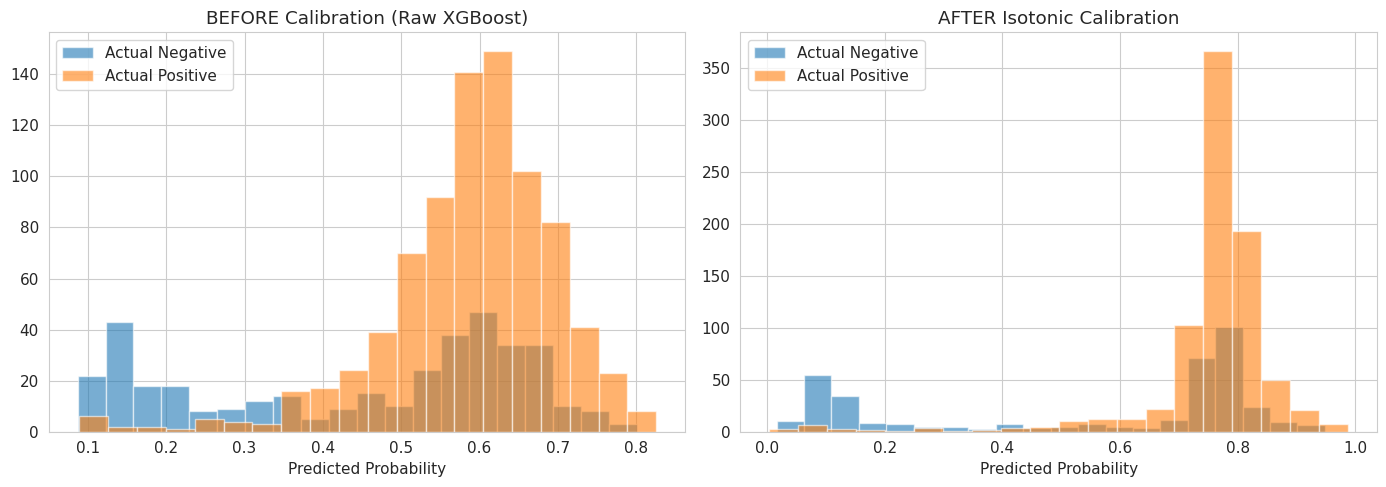

Note: After calibration, probabilities should spread more clearly between classes,
instead of clustering tightly around a single value.


In [154]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(oof_probs_raw[y_train == 0], bins=20, alpha=0.6, label='Actual Negative')
axes[0].hist(oof_probs_raw[y_train == 1], bins=20, alpha=0.6, label='Actual Positive')
axes[0].set_title("BEFORE Calibration (Raw XGBoost)")
axes[0].set_xlabel("Predicted Probability")
axes[0].legend()

axes[1].hist(oof_probs_calibrated[y_train == 0], bins=20, alpha=0.6, label='Actual Negative')
axes[1].hist(oof_probs_calibrated[y_train == 1], bins=20, alpha=0.6, label='Actual Positive')
axes[1].set_title("AFTER Isotonic Calibration")
axes[1].set_xlabel("Predicted Probability")
axes[1].legend()

plt.tight_layout()
plt.show()

print("Note: After calibration, probabilities should spread more clearly between classes,")
print("instead of clustering tightly around a single value.")

In [155]:
fpr_tr, tpr_tr, thresh_tr = roc_curve(y_train, oof_probs_calibrated)
youden_j = tpr_tr - fpr_tr
best_thresh = thresh_tr[np.argmax(youden_j)]
print(f"Optimal threshold (Youden's J, calibrated, training CV only): {best_thresh:.4f}")

# Apply frozen calibrated model + threshold to the untouched test set (used exactly once)
y_prob_D = calibrated_model.predict_proba(X_full_test)[:, 1]
y_pred_D_default = (y_prob_D >= 0.5).astype(int)
y_pred_D_optimal = (y_prob_D >= best_thresh).astype(int)

metrics_D_default = calculate_metrics(y_test, y_pred_D_default, y_prob_D)
metrics_D_optimal = calculate_metrics(y_test, y_pred_D_optimal, y_prob_D)

threshold_comparison = pd.DataFrame({
    'Default (0.5)': metrics_D_default,
    f'Optimal ({best_thresh:.3f})': metrics_D_optimal
}).T
threshold_comparison.round(4)

Optimal threshold (Youden's J, calibrated, training CV only): 0.6316


,Accuracy,Precision,Recall,Specificity,F1,ROC-AUC,PR-AUC,MCC
Default (0.5),0.7558,0.7481,0.9712,0.2842,0.8452,0.6701,0.7865,0.3803
Optimal (0.632),0.7591,0.7567,0.9567,0.3263,0.8450,0.6701,0.7865,0.3879


In [156]:
y_pred_D = y_pred_D_optimal
metrics_D = metrics_D_optimal
final_dchss_xgb_model = calibrated_model

print(f"=== FINAL MODEL ({best_candidate_name} + Isotonic Calibration) ===\n")
for k, v in metrics_D.items():
    print(f"{k}: {v:.4f}")

=== FINAL MODEL (XGBoost (Full Features) + Isotonic Calibration) ===

Accuracy: 0.7591
Precision: 0.7567
Recall: 0.9567
Specificity: 0.3263
F1: 0.8450
ROC-AUC: 0.6701
PR-AUC: 0.7865
MCC: 0.3879


## Reliability Table: Making Probability Meaning Clear

This table directly answers the complaint "51% বনাম 95% দুটোই positive দেখায় কেন?" —
it shows the ACTUAL dengue positive rate within each predicted-probability bin on the
test set. A well-calibrated model should show rising actual positive rate as the
predicted probability bin increases.

In [157]:
prob_bins = [0, 0.2, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.01]
bin_labels = ['0-20%', '20-40%', '40-50%', '50-60%', '60-70%', '70-80%', '80-90%', '90-100%']

reliability_df = pd.DataFrame({'predicted_prob': y_prob_D, 'actual': y_test.values})
reliability_df['prob_bin'] = pd.cut(reliability_df['predicted_prob'], bins=prob_bins, labels=bin_labels, right=False)

reliability_table = reliability_df.groupby('prob_bin').agg(
    N=('actual', 'count'),
    Actual_Dengue_Rate=('actual', 'mean')
).reindex(bin_labels)

print("Reliability Table (Test Set) — Predicted Probability Bin vs Actual Dengue Rate:")
reliability_table

Reliability Table (Test Set) — Predicted Probability Bin vs Actual Dengue Rate:


,N,Actual_Dengue_Rate
prob_bin,,
0-20%,28,0.142857
20-40%,3,0.333333
40-50%,2,0.500000
50-60%,5,0.400000
60-70%,14,0.642857
70-80%,202,0.762376
80-90%,40,0.700000
90-100%,9,1.000000


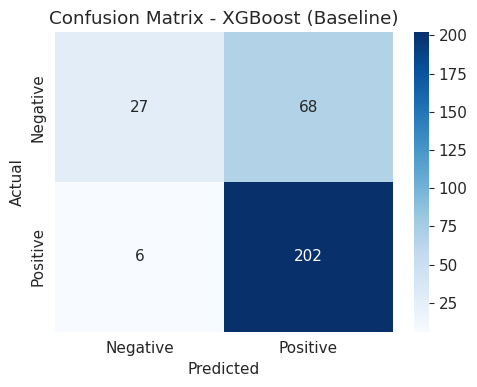

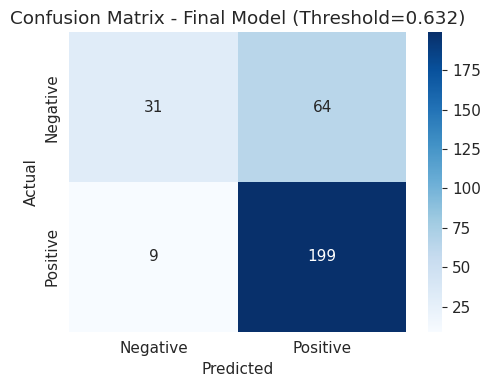

In [158]:
def plot_confusion(y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=['Negative','Positive'], yticklabels=['Negative','Positive'])
    plt.title(title); plt.xlabel("Predicted"); plt.ylabel("Actual")
    plt.tight_layout(); plt.show()

best_baseline_name = baseline_results_df['ROC-AUC'].idxmax()
best_baseline_model = best_models[best_baseline_name]
X_use_best = X_raw_test_scaled if best_baseline_name in ['Logistic Regression','SVM'] else X_raw_test
y_pred_best_baseline = best_baseline_model.predict(X_use_best)

plot_confusion(y_test, y_pred_best_baseline, f"Confusion Matrix - {best_baseline_name} (Baseline)")
plot_confusion(y_test, y_pred_D, f"Confusion Matrix - Final Model (Threshold={best_thresh:.3f})")

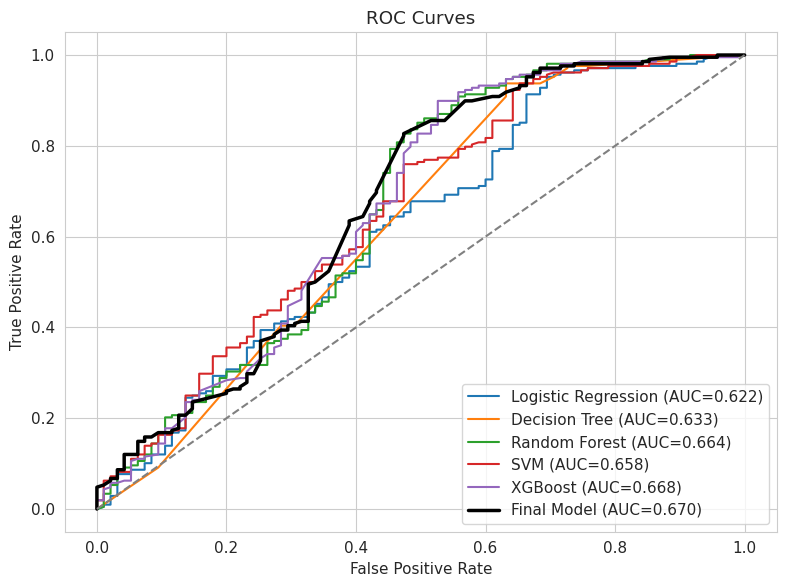

In [159]:
plt.figure(figsize=(8,6))
for name, model in best_models.items():
    X_use_test = X_raw_test_scaled if name in ['Logistic Regression','SVM'] else X_raw_test
    y_prob = model.predict_proba(X_use_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    plt.plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test,y_prob):.3f})")

fpr_d, tpr_d, _ = roc_curve(y_test, y_prob_D)
plt.plot(fpr_d, tpr_d, label=f"Final Model (AUC={roc_auc_score(y_test,y_prob_D):.3f})", linewidth=2.5, color='black')
plt.plot([0,1],[0,1], linestyle='--', color='gray')
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("ROC Curves"); plt.legend(loc='lower right'); plt.tight_layout(); plt.show()

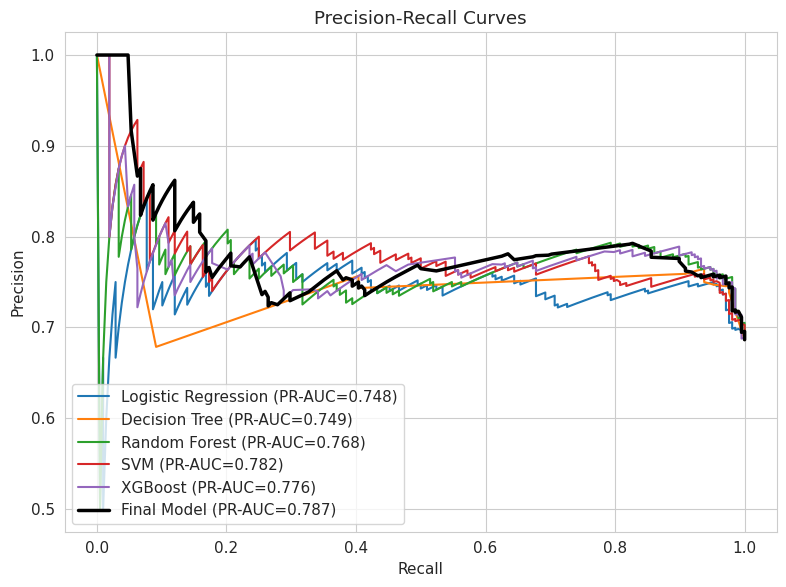

In [160]:
plt.figure(figsize=(8,6))
for name, model in best_models.items():
    X_use_test = X_raw_test_scaled if name in ['Logistic Regression','SVM'] else X_raw_test
    y_prob = model.predict_proba(X_use_test)[:, 1]
    precision, recall, _ = precision_recall_curve(y_test, y_prob)
    plt.plot(recall, precision, label=f"{name} (PR-AUC={average_precision_score(y_test,y_prob):.3f})")

precision_d, recall_d, _ = precision_recall_curve(y_test, y_prob_D)
plt.plot(recall_d, precision_d, label=f"Final Model (PR-AUC={average_precision_score(y_test,y_prob_D):.3f})",
         linewidth=2.5, color='black')
plt.xlabel("Recall"); plt.ylabel("Precision"); plt.title("Precision-Recall Curves")
plt.legend(loc='lower left'); plt.tight_layout(); plt.show()

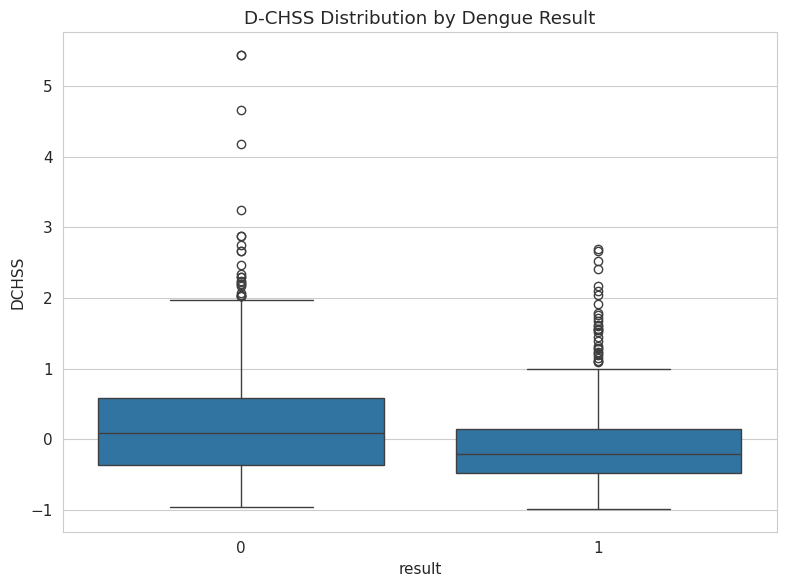

Mann-Whitney U test: U=179822.50, p=0.000000


In [161]:
dchss_all = pd.concat([
    df_train[['DCHSS']].assign(result=y_train.values),
    df_test[['DCHSS']].assign(result=y_test.values)
], axis=0)

plt.figure(figsize=(8,6))
sns.boxplot(x='result', y='DCHSS', data=dchss_all)
plt.title("D-CHSS Distribution by Dengue Result")
plt.tight_layout(); plt.show()

group_pos = dchss_all[dchss_all['result']==1]['DCHSS']
group_neg = dchss_all[dchss_all['result']==0]['DCHSS']
u_stat, p_val = mannwhitneyu(group_pos, group_neg, alternative='two-sided')
print(f"Mann-Whitney U test: U={u_stat:.2f}, p={p_val:.6f}")

Spearman correlation (D-CHSS vs calibrated probability): r=-0.5492, p=0.000000


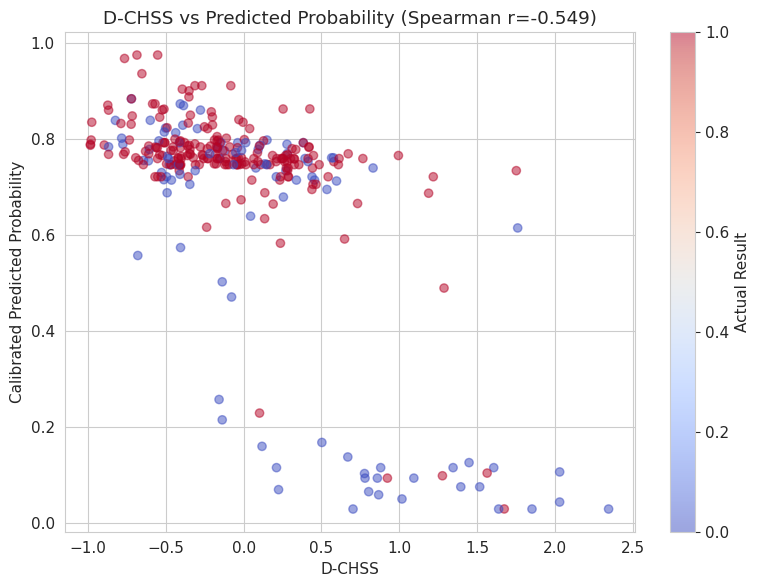

In [162]:
corr, p_corr = spearmanr(df_test['DCHSS'], y_prob_D)
print(f"Spearman correlation (D-CHSS vs calibrated probability): r={corr:.4f}, p={p_corr:.6f}")

plt.figure(figsize=(8,6))
sc = plt.scatter(df_test['DCHSS'], y_prob_D, alpha=0.5, c=y_test, cmap='coolwarm')
plt.xlabel("D-CHSS"); plt.ylabel("Calibrated Predicted Probability")
plt.title(f"D-CHSS vs Predicted Probability (Spearman r={corr:.3f})")
plt.colorbar(sc, label="Actual Result"); plt.tight_layout(); plt.show()

In [163]:
low_thresh, high_thresh = np.percentile(df_train['DCHSS'], [33.33, 66.67])
print(f"Risk Thresholds: Low < {low_thresh:.4f} <= Moderate <= {high_thresh:.4f} < High")

def assign_risk_group(score):
    if score < low_thresh: return 'Low'
    elif score <= high_thresh: return 'Moderate'
    else: return 'High'

df_test['risk_group'] = df_test['DCHSS'].apply(assign_risk_group)
risk_summary = df_test.groupby('risk_group').apply(lambda g: pd.Series({
    'N': len(g), 'Dengue Positive Rate': g['result_bin'].mean()
})).reindex(['Low','Moderate','High'])
risk_summary

Risk Thresholds: Low < -0.3488 <= Moderate <= 0.1128 < High


,N,Dengue Positive Rate
risk_group,,
Low,103.0,0.718447
Moderate,96.0,0.770833
High,104.0,0.576923


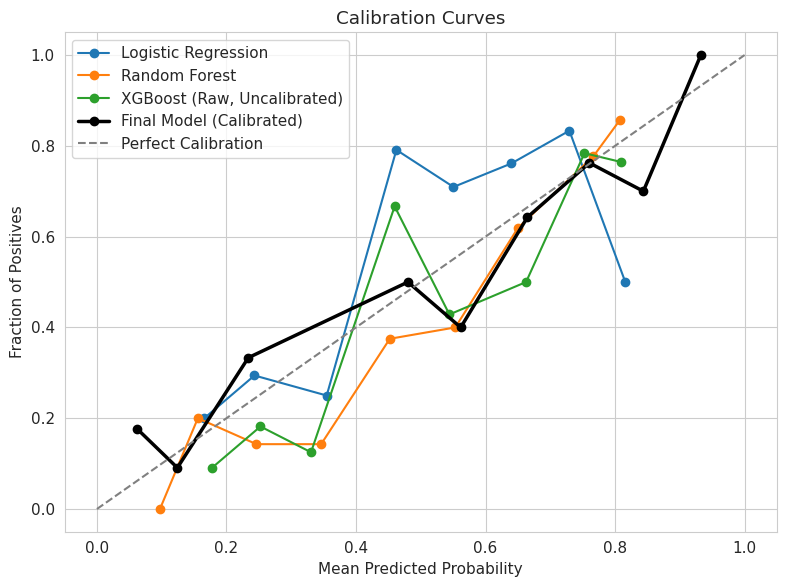

Brier Scores (lower=better):
  Logistic Regression: 0.2264
  Random Forest: 0.1774
  XGBoost (Raw, Uncalibrated): 0.1789
  Final Model (Calibrated): 0.1807


In [164]:
plt.figure(figsize=(8,6))
models_for_cal = {
    'Logistic Regression': (best_models['Logistic Regression'], X_raw_test_scaled),
    'Random Forest': (best_models['Random Forest'], X_raw_test),
    'XGBoost (Raw, Uncalibrated)': (best_models['XGBoost'], X_raw_test),
}

brier_scores = {}
for name, (model, X_use) in models_for_cal.items():
    y_prob = model.predict_proba(X_use)[:, 1]
    frac_pos, mean_pred = calibration_curve(y_test, y_prob, n_bins=10)
    plt.plot(mean_pred, frac_pos, marker='o', label=name)
    brier_scores[name] = brier_score_loss(y_test, y_prob)

frac_pos_final, mean_pred_final = calibration_curve(y_test, y_prob_D, n_bins=10)
plt.plot(mean_pred_final, frac_pos_final, marker='o', linewidth=2.5, color='black',
         label='Final Model (Calibrated)')
brier_scores['Final Model (Calibrated)'] = brier_score_loss(y_test, y_prob_D)

plt.plot([0,1],[0,1], linestyle='--', color='gray', label='Perfect Calibration')
plt.xlabel("Mean Predicted Probability"); plt.ylabel("Fraction of Positives")
plt.title("Calibration Curves"); plt.legend(); plt.tight_layout(); plt.show()

print("Brier Scores (lower=better):")
for k, v in brier_scores.items():
    print(f"  {k}: {v:.4f}")

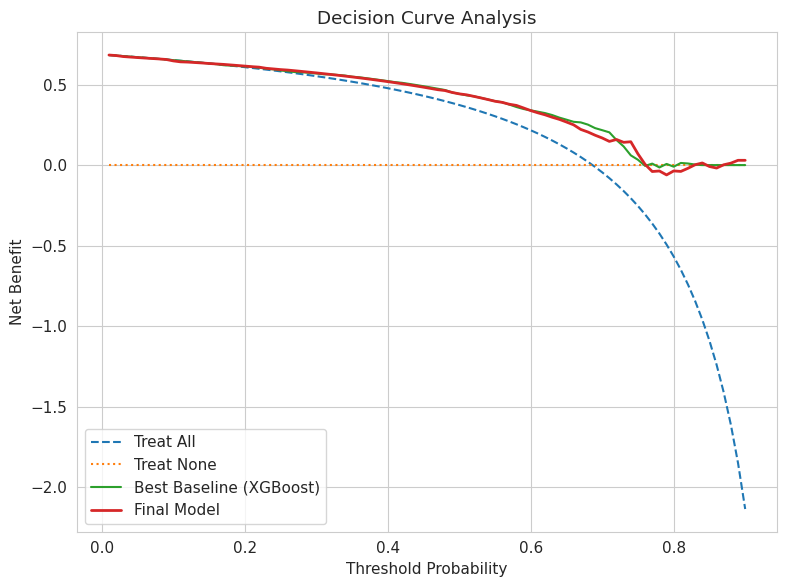

In [165]:
def net_benefit(y_true, y_prob, thresholds):
    n = len(y_true); nb = []
    for pt in thresholds:
        pred_pos = (y_prob >= pt).astype(int)
        tp = np.sum((pred_pos==1)&(y_true==1)); fp = np.sum((pred_pos==1)&(y_true==0))
        nb.append((tp/n) - (fp/n)*(pt/(1-pt)))
    return np.array(nb)

thresholds_dca = np.arange(0.01, 0.91, 0.01)
prevalence = y_test.mean()
nb_all = prevalence - (1-prevalence)*(thresholds_dca/(1-thresholds_dca))
nb_none = np.zeros(len(thresholds_dca))

y_prob_baseline_cal = best_baseline_model.predict_proba(X_use_best)[:, 1]
nb_baseline = net_benefit(y_test.values, y_prob_baseline_cal, thresholds_dca)
nb_final = net_benefit(y_test.values, y_prob_D, thresholds_dca)

plt.figure(figsize=(8,6))
plt.plot(thresholds_dca, nb_all, label='Treat All', linestyle='--')
plt.plot(thresholds_dca, nb_none, label='Treat None', linestyle=':')
plt.plot(thresholds_dca, nb_baseline, label=f'Best Baseline ({best_baseline_name})')
plt.plot(thresholds_dca, nb_final, label='Final Model', linewidth=2)
plt.xlabel("Threshold Probability"); plt.ylabel("Net Benefit")
plt.title("Decision Curve Analysis"); plt.legend(); plt.tight_layout(); plt.show()

## SHAP Explainability

SHAP requires a tree-based model. Since the final model may be wrapped in calibration,
we use the underlying XGBoost component (`final_base_model`, same features) for SHAP
explanation — this reflects identical feature contributions.

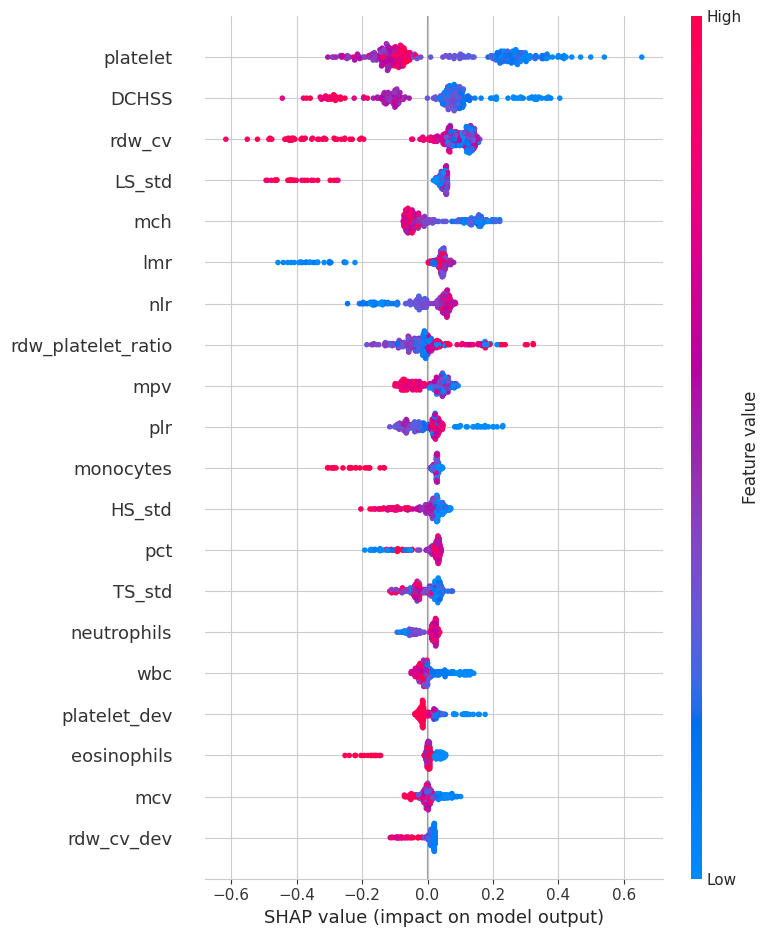

In [166]:
shap_model = xgb.XGBClassifier(**dchss_best_params, random_state=RANDOM_STATE, eval_metric='logloss')
shap_model.fit(X_full_train, y_train)

explainer = shap.TreeExplainer(shap_model)
shap_values = explainer.shap_values(X_full_test)
shap.summary_plot(shap_values, X_full_test, show=True)

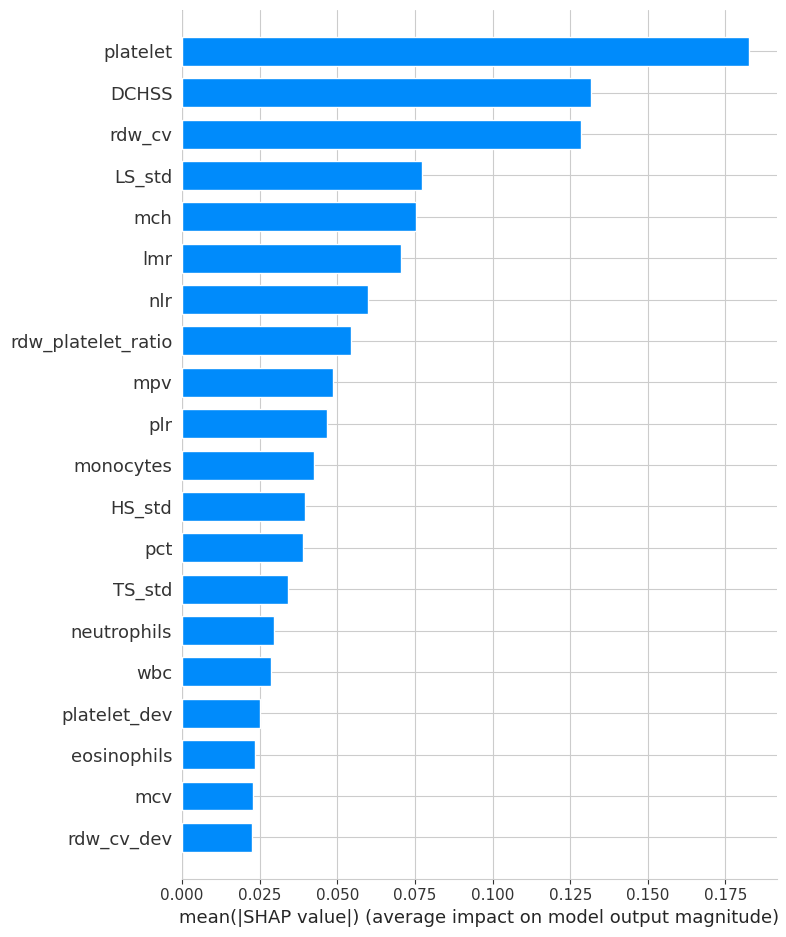


Patient 0 - Actual: 0, Calibrated Predicted Prob: 0.8733


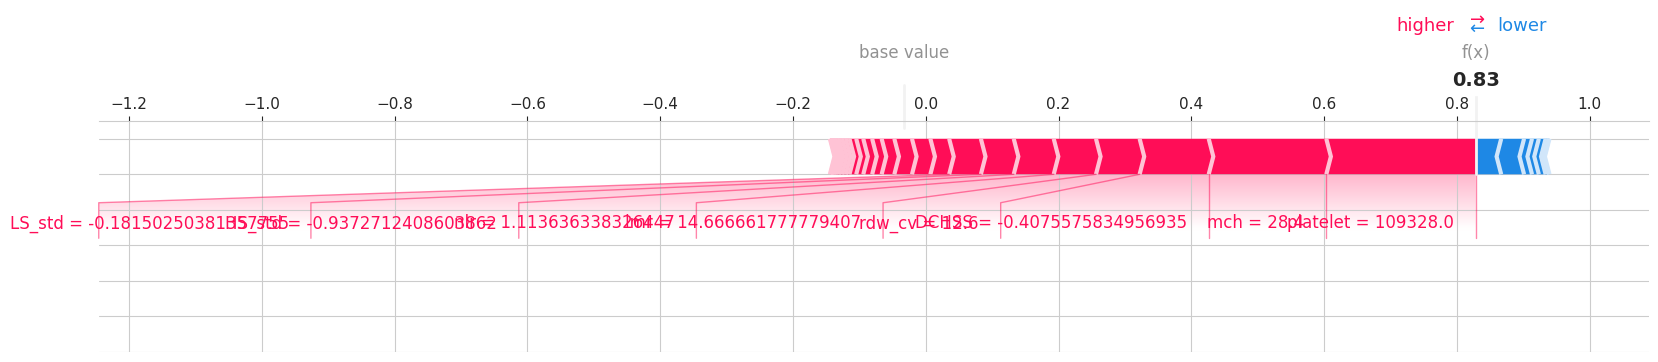


Patient 1 - Actual: 1, Calibrated Predicted Prob: 0.7799


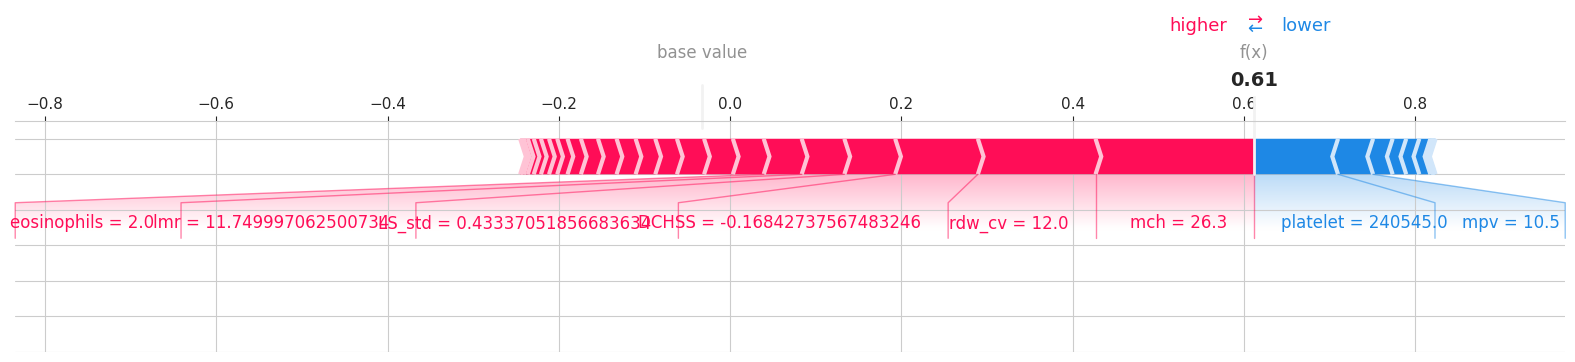


Patient 2 - Actual: 0, Calibrated Predicted Prob: 0.7546


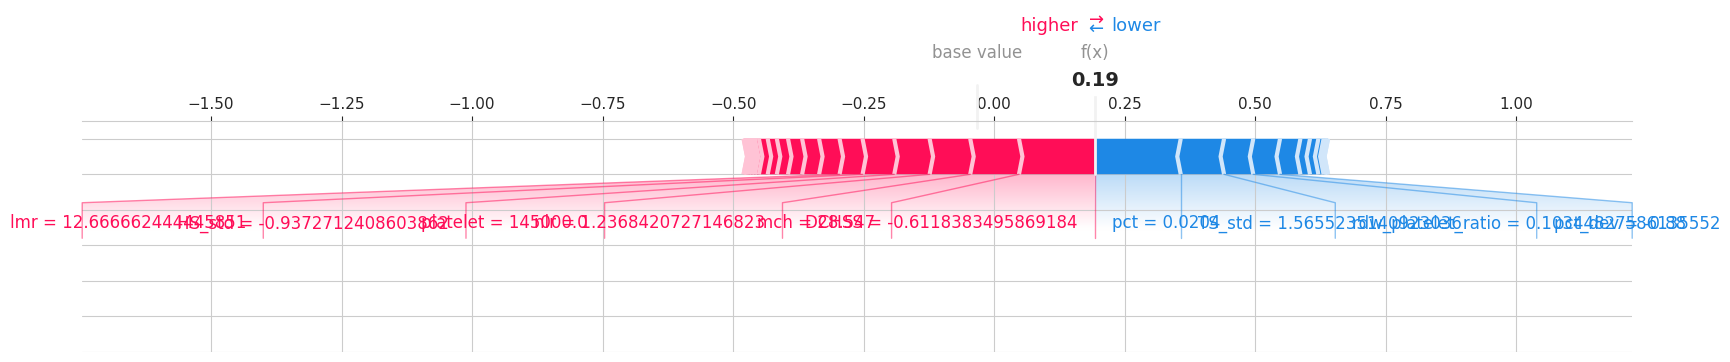

In [167]:
shap.summary_plot(shap_values, X_full_test, plot_type='bar', show=True)

for i in range(3):
    print(f"\nPatient {i} - Actual: {y_test.iloc[i]}, Calibrated Predicted Prob: {y_prob_D[i]:.4f}")
    shap.force_plot(explainer.expected_value, shap_values[i], X_full_test.iloc[i],
                     matplotlib=True, show=True)

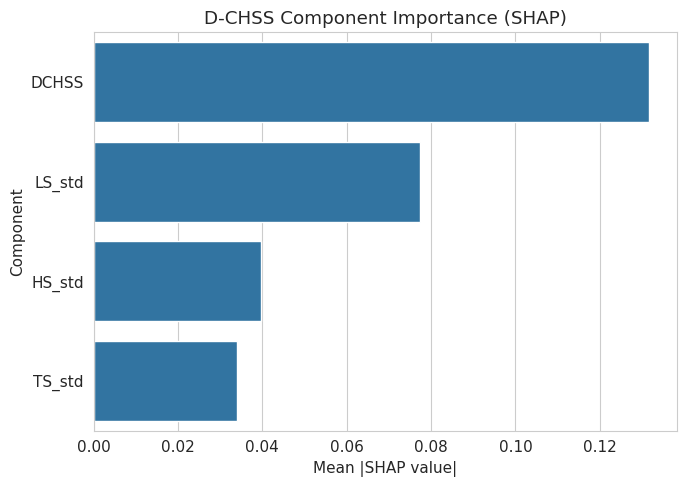

,Component,Mean |SHAP value|
3,DCHSS,0.131723
1,LS_std,0.077385
2,HS_std,0.039587
0,TS_std,0.033993


In [168]:
component_cols_idx = [X_full_test.columns.get_loc(c) for c in DCHSS_COMPONENT_FEATURES]
mean_abs_shap_components = np.abs(shap_values[:, component_cols_idx]).mean(axis=0)
component_importance_df = pd.DataFrame({
    'Component': DCHSS_COMPONENT_FEATURES, 'Mean |SHAP value|': mean_abs_shap_components
}).sort_values('Mean |SHAP value|', ascending=False)

plt.figure(figsize=(7,5))
sns.barplot(x='Mean |SHAP value|', y='Component', data=component_importance_df)
plt.title("D-CHSS Component Importance (SHAP)")
plt.tight_layout(); plt.show()
component_importance_df

In [169]:
explainer_A = shap.TreeExplainer(model_A)
shap_values_A = explainer_A.shap_values(X_raw_test)
raw_importance_df = pd.DataFrame({
    'Feature': CBC_FEATURES, 'Mean |SHAP value|': np.abs(shap_values_A).mean(axis=0)
}).sort_values('Mean |SHAP value|', ascending=False)

print("Raw CBC Feature Importance (SHAP):")
raw_importance_df

Raw CBC Feature Importance (SHAP):


,Feature,Mean |SHAP value|
11,platelet,0.236264
10,rdw_cv,0.186536
1,neutrophils,0.142637
3,monocytes,0.100381
14,pct,0.089940
8,mch,0.083612
12,mpv,0.059387
7,mcv,0.034657
5,rbc,0.034603
15,wbc,0.034009


In [170]:
both_correct = np.sum((y_pred_best_baseline==y_test.values)&(y_pred_D==y_test.values))
baseline_only = np.sum((y_pred_best_baseline==y_test.values)&(y_pred_D!=y_test.values))
final_only = np.sum((y_pred_best_baseline!=y_test.values)&(y_pred_D==y_test.values))
both_wrong = np.sum((y_pred_best_baseline!=y_test.values)&(y_pred_D!=y_test.values))

contingency_table = [[both_correct, baseline_only],[final_only, both_wrong]]
print(pd.DataFrame(contingency_table, index=['Baseline Correct','Baseline Wrong'],
                    columns=['Final Correct','Final Wrong']))

mcnemar_result = mcnemar(contingency_table, exact=True)
print(f"\nMcNemar statistic: {mcnemar_result.statistic:.4f}, p-value: {mcnemar_result.pvalue:.6f}")

                  Final Correct  Final Wrong
Baseline Correct            223            6
Baseline Wrong                7           67

McNemar statistic: 6.0000, p-value: 1.000000


In [171]:
def dchss_cv_evaluation(df_train_full, y_train_full, n_splits=5):
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=RANDOM_STATE)
    fold_metrics = {'Accuracy':[], 'Precision':[], 'Recall':[], 'F1':[], 'ROC-AUC':[]}
    df_train_full = df_train_full.reset_index(drop=True)
    y_train_full = y_train_full.reset_index(drop=True)

    for tr_idx, val_idx in skf.split(df_train_full, y_train_full):
        fold_train = df_train_full.iloc[tr_idx].copy()
        fold_val = df_train_full.iloc[val_idx].copy()
        y_ft = y_train_full.iloc[tr_idx]; y_fv = y_train_full.iloc[val_idx]

        fold_scaler = StandardScaler()
        fold_scaler.fit(fold_train[['TS_raw','LS_raw','HS_raw']])
        tr_std = fold_scaler.transform(fold_train[['TS_raw','LS_raw','HS_raw']])
        va_std = fold_scaler.transform(fold_val[['TS_raw','LS_raw','HS_raw']])
        fold_train['TS_std'],fold_train['LS_std'],fold_train['HS_std'] = tr_std[:,0],tr_std[:,1],tr_std[:,2]
        fold_val['TS_std'],fold_val['LS_std'],fold_val['HS_std'] = va_std[:,0],va_std[:,1],va_std[:,2]

        fold_lr = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
        fold_lr.fit(fold_train[['TS_std','LS_std','HS_std']], y_ft)
        fc = np.abs(fold_lr.coef_[0]); fw = fc/fc.sum()
        fold_train['DCHSS'] = fw[0]*fold_train['TS_std']+fw[1]*fold_train['LS_std']+fw[2]*fold_train['HS_std']
        fold_val['DCHSS'] = fw[0]*fold_val['TS_std']+fw[1]*fold_val['LS_std']+fw[2]*fold_val['HS_std']

        fold_base = clone(final_base_model)
        fold_base.fit(fold_train[FULL_FEATURES], y_ft)
        fold_calibrated = CalibratedClassifierCV(fold_base, method='isotonic', cv=3)
        fold_calibrated.fit(fold_train[FULL_FEATURES], y_ft)

        fpb = fold_calibrated.predict_proba(fold_val[FULL_FEATURES])[:, 1]
        fp = (fpb >= 0.5).astype(int)

        fold_metrics['Accuracy'].append(accuracy_score(y_fv, fp))
        fold_metrics['Precision'].append(precision_score(y_fv, fp, zero_division=0))
        fold_metrics['Recall'].append(recall_score(y_fv, fp, zero_division=0))
        fold_metrics['F1'].append(f1_score(y_fv, fp, zero_division=0))
        fold_metrics['ROC-AUC'].append(roc_auc_score(y_fv, fpb))
    return fold_metrics

cv_fold_metrics = dchss_cv_evaluation(df_train, y_train, n_splits=5)
print("5-Fold CV Results (Leakage-Safe, Final Pipeline):")
for metric, values in cv_fold_metrics.items():
    print(f"  {metric}: {np.mean(values):.4f} +/- {np.std(values):.4f}")

5-Fold CV Results (Leakage-Safe, Final Pipeline):
  Accuracy: 0.7682 +/- 0.0258
  Precision: 0.7634 +/- 0.0271
  Recall: 0.9613 +/- 0.0119
  F1: 0.8506 +/- 0.0139
  ROC-AUC: 0.6792 +/- 0.0501


FINAL HOLD-OUT TEST PERFORMANCE (XGBoost (Full Features) + Calibration) 

Accuracy: 0.7591
Precision: 0.7567
Recall: 0.9567
Specificity: 0.3263
F1: 0.8450
ROC-AUC: 0.6701
PR-AUC: 0.7865
MCC: 0.3879


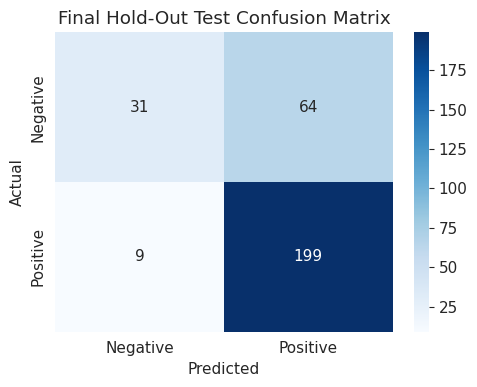

In [172]:
print(f"FINAL HOLD-OUT TEST PERFORMANCE ({best_candidate_name} + Calibration) \n")
for k, v in metrics_D.items():
    print(f"{k}: {v:.4f}")
plot_confusion(y_test, y_pred_D, "Final Hold-Out Test Confusion Matrix")

In [173]:
sample_idx = [0, 1, 2]
y_prob_uncalibrated = final_base_model.predict_proba(X_full_test)[:, 1]

for idx in sample_idx:
    patient = df_test.iloc[idx]
    print(f"\n       TEST PATIENT INDEX {idx}          ")
    print(f"Platelet: {patient['platelet']} ({patient['platelet_state']}), "
          f"RDW-CV: {patient['rdw_cv']} ({patient['rdw_cv_state']}), "
          f"NLR: {patient['nlr']:.2f}")
    print(f"D-CHSS: {patient['DCHSS']:.4f}, Risk Group: {patient['risk_group']}")
    print(f"Uncalibrated Probability: {y_prob_uncalibrated[idx]:.4f}")
    print(f"Calibrated Probability:   {y_prob_D[idx]:.4f}")
    print(f"Threshold: {best_thresh:.4f}")
    print(f"Final Prediction: {'Positive' if y_pred_D[idx]==1 else 'Negative'}")
    print(f"Actual Result: {'Positive' if y_test.iloc[idx]==1 else 'Negative'}")

print("\nNOTE: Research demonstration only - NOT a medical diagnosis tool.")


       TEST PATIENT INDEX 0          
Platelet: 109328.0 (LOW), RDW-CV: 12.6 (NORMAL), NLR: 1.11
D-CHSS: -0.4076, Risk Group: Low
Uncalibrated Probability: 0.6960
Calibrated Probability:   0.8733
Threshold: 0.6316
Final Prediction: Positive
Actual Result: Negative

       TEST PATIENT INDEX 1          
Platelet: 240545.0 (NORMAL), RDW-CV: 12.0 (NORMAL), NLR: 0.98
D-CHSS: -0.1684, Risk Group: Moderate
Uncalibrated Probability: 0.6483
Calibrated Probability:   0.7799
Threshold: 0.6316
Final Prediction: Positive
Actual Result: Positive

       TEST PATIENT INDEX 2          
Platelet: 145000.0 (LOW), RDW-CV: 15.0 (HIGH), NLR: 1.24
D-CHSS: -0.6118, Risk Group: Low
Uncalibrated Probability: 0.5479
Calibrated Probability:   0.7546
Threshold: 0.6316
Final Prediction: Positive
Actual Result: Negative

NOTE: Research demonstration only - NOT a medical diagnosis tool.


In [174]:
final_results = baseline_results_df.copy()
final_results.loc['Deviation + XGBoost'] = metrics_B
final_results.loc['D-CHSS + XGBoost'] = metrics_C
final_results.loc[f'Final Proposed ({best_candidate_name} + Calibration)'] = metrics_D
final_results = final_results[['Accuracy','Precision','Recall','Specificity','F1','ROC-AUC','PR-AUC','MCC']]
final_results.round(4)

,Accuracy,Precision,Recall,Specificity,F1,ROC-AUC,PR-AUC,MCC
Logistic Regression,0.6172,0.7323,0.6971,0.4421,0.7143,0.6216,0.7478,0.1357
Decision Tree,0.7492,0.7619,0.9231,0.3684,0.8348,0.6334,0.7488,0.3614
Random Forest,0.7591,0.7528,0.9663,0.3053,0.8463,0.6635,0.7682,0.3894
SVM,0.7195,0.7173,0.9760,0.1579,0.8269,0.6584,0.7816,0.2501
XGBoost,0.7558,0.7481,0.9712,0.2842,0.8452,0.6684,0.7758,0.3803
Deviation + XGBoost,0.7327,0.7571,0.8990,0.3684,0.8220,0.6228,0.7455,0.3197
D-CHSS + XGBoost,0.6832,0.7569,0.7933,0.4421,0.7746,0.5969,0.7151,0.2431
Final Proposed (XGBoost (Full Features) + Calibration),0.7591,0.7567,0.9567,0.3263,0.8450,0.6701,0.7865,0.3879


In [175]:
final_ablation_table = pd.DataFrame({
    'Feature Strategy': ['Raw CBC', 'Deviation', 'D-CHSS', 'Raw+Deviation+D-CHSS+Ratios (Calibrated)'],
    'ROC-AUC': [metrics_A['ROC-AUC'], metrics_B['ROC-AUC'], metrics_C['ROC-AUC'], metrics_D['ROC-AUC']],
    'F1': [metrics_A['F1'], metrics_B['F1'], metrics_C['F1'], metrics_D['F1']],
    'Recall': [metrics_A['Recall'], metrics_B['Recall'], metrics_C['Recall'], metrics_D['Recall']],
    'Specificity': [metrics_A['Specificity'], metrics_B['Specificity'], metrics_C['Specificity'], metrics_D['Specificity']]
})
final_ablation_table.round(4)

,Feature Strategy,ROC-AUC,F1,Recall,Specificity
0,Raw CBC,0.6521,0.8285,0.8942,0.4211
1,Deviation,0.6228,0.8220,0.8990,0.3684
2,D-CHSS,0.5969,0.7746,0.7933,0.4421
3,Raw+Deviation+D-CHSS+Ratios (Calibrated),0.6701,0.8450,0.9567,0.3263


In [176]:
best_baseline_auc = baseline_results_df.loc[best_baseline_name, 'ROC-AUC']
component_names = ['Thrombocytopenia Score', 'Leukocyte Response Score', 'Hemoconcentration Score']
most_informative_component = component_names[int(np.argmax([w_ts, w_ls, w_hs]))]
brier_final = brier_scores['Final Model (Calibrated)']
calibration_quality = "well-calibrated" if brier_final < 0.20 else ("moderately calibrated" if brier_final < 0.25 else "poorly calibrated")
cv_auc_mean = np.mean(cv_fold_metrics['ROC-AUC']); cv_auc_std = np.std(cv_fold_metrics['ROC-AUC'])

summary = f"""
=== AUTOMATED RESEARCH SUMMARY ===

1. Best baseline model: {best_baseline_name} (Test ROC-AUC = {best_baseline_auc:.4f})
2. Final model: {best_candidate_name} + Isotonic Calibration
   Test ROC-AUC = {metrics_D['ROC-AUC']:.4f}, Accuracy = {metrics_D['Accuracy']:.4f},
   Specificity = {metrics_D['Specificity']:.4f}
3. Most informative D-CHSS component: {most_informative_component}
4. Calibration: Brier Score = {brier_final:.4f} ({calibration_quality})
   -> Probability spread is now clinically interpretable (see reliability table).
5. Most important raw CBC parameter (SHAP): {raw_importance_df.iloc[0]['Feature']}
6. Cross-validation stability (5-fold, leakage-safe): ROC-AUC = {cv_auc_mean:.4f} +/- {cv_auc_std:.4f}
7. Final classification threshold: {best_thresh:.4f}

This summary is generated directly from actual computed results of this notebook run.
"""
print(summary)


=== AUTOMATED RESEARCH SUMMARY ===

1. Best baseline model: XGBoost (Test ROC-AUC = 0.6684)
2. Final model: XGBoost (Full Features) + Isotonic Calibration
   Test ROC-AUC = 0.6701, Accuracy = 0.7591,
   Specificity = 0.3263
3. Most informative D-CHSS component: Leukocyte Response Score
4. Calibration: Brier Score = 0.1807 (well-calibrated)
   -> Probability spread is now clinically interpretable (see reliability table).
5. Most important raw CBC parameter (SHAP): platelet
6. Cross-validation stability (5-fold, leakage-safe): ROC-AUC = 0.6792 +/- 0.0501
7. Final classification threshold: 0.6316

This summary is generated directly from actual computed results of this notebook run.



In [179]:
import os
import pickle

artifact = {
    'model': final_dchss_xgb_model,
    'base_model_type': best_candidate_name,
    'classification_threshold': best_thresh,
    'reference_ranges': REFERENCE_RANGES,
    'sex_specific_params': SEX_SPECIFIC_PARAMS,
    'max_deviation_cap': MAX_DEV,
    'cbc_features': CBC_FEATURES,
    'dev_features': DEV_FEATURES,
    'dchss_component_features': DCHSS_COMPONENT_FEATURES,
    'ratio_features': RATIO_FEATURES,
    'full_feature_columns': FULL_FEATURES,
    'imputer_num': imputer_num,
    'imputer_cat': imputer_cat,
    'component_scaler': component_scaler,
    'weight_logreg': weight_logreg,
    'dchss_weights': {
        'w_ts': w_ts,
        'w_ls': w_ls,
        'w_hs': w_hs
    },
    'risk_thresholds': {
        'low_thresh': low_thresh,
        'high_thresh': high_thresh
    },
    'gender_mapping': gender_mapping,
    'result_mapping': result_mapping,
    'reliability_table': reliability_table
}

os.makedirs('/kaggle/working', exist_ok=True)

file_path = '/kaggle/working/dchss_model.pkl'

with open(file_path, 'wb') as f:
    pickle.dump(artifact, f)

print("Model saved:", file_path)
print("File size:", round(os.path.getsize(file_path) / (1024 * 1024), 2), "MB")

Model saved: /kaggle/working/dchss_model.pkl
File size: 0.68 MB
